In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

from scipy.sparse import csr_matrix
from implicit.bpr import BayesianPersonalizedRanking

# Project directories
project = Path(
    "/Users/ogechikaesedebe/Downloads/Activity-Recommendation-System"
)

split_dir = project / "data" / "splits_60_20_20"
models_dir = project / "models"
results_dir = project / "results"

# Confirm required files exist
required_files = [
    split_dir / "train.csv",
    split_dir / "validation.csv",
    split_dir / "validation_sample_1000_users.csv",
    models_dir / "bpr_60_20_20_50_iterations.npz"
]

print("REQUIRED FILE CHECK")

for file in required_files:
    print(
        f"{'FOUND' if file.exists() else 'MISSING'}: "
        f"{file.name}"
    )

REQUIRED FILE CHECK
FOUND: train.csv
FOUND: validation.csv
FOUND: validation_sample_1000_users.csv
FOUND: bpr_60_20_20_50_iterations.npz


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Load training interactions
train_df = pd.read_csv(
    split_dir / "train.csv",
    dtype={
        "user_id": "string",
        "gmap_id": "string"
    },
    usecols=["user_id", "gmap_id"]
)

# Encode users and activities
user_indices, unique_users = pd.factorize(
    train_df["user_id"],
    sort=True
)

activity_indices, unique_activities = pd.factorize(
    train_df["gmap_id"],
    sort=True
)

# Create ID mappings
user_to_index = {
    user_id: idx
    for idx, user_id in enumerate(unique_users)
}

activity_to_index = {
    activity_id: idx
    for idx, activity_id in enumerate(unique_activities)
}

index_to_user = {
    idx: user_id
    for idx, user_id in enumerate(unique_users)
}

index_to_activity = {
    idx: activity_id
    for idx, activity_id in enumerate(unique_activities)
}

# Dataset dimensions
num_users = len(unique_users)
num_activities = len(unique_activities)

print("TRAINING DATA")
print("Total interactions:", len(train_df))
print("Unique users:", num_users)
print("Unique activities:", num_activities)

TRAINING DATA
Total interactions: 6303944
Unique users: 627365
Unique activities: 69783


In [3]:
# Construct sparse user–activity matrix
user_activity_matrix = csr_matrix(
    (
        np.ones(len(train_df), dtype=np.float32),
        (user_indices, activity_indices)
    ),
    shape=(num_users, num_activities),
    dtype=np.float32
)

# Calculate matrix density
density = (
    user_activity_matrix.nnz
    / (num_users * num_activities)
) * 100

print("USER–ACTIVITY MATRIX")
print("Matrix shape:", user_activity_matrix.shape)
print("Non-zero interactions:", user_activity_matrix.nnz)
print(f"Matrix density: {density:.4f}%")
print(f"Matrix memory: {(
    user_activity_matrix.data.nbytes
    + user_activity_matrix.indices.nbytes
    + user_activity_matrix.indptr.nbytes
) / (1024 ** 2):.2f} MB")

USER–ACTIVITY MATRIX
Matrix shape: (627365, 69783)
Non-zero interactions: 6303944
Matrix density: 0.0144%
Matrix memory: 50.49 MB


## Experiment 1: Training BPR with 32 Latent Factors

In [4]:
# Initialize BPR with 32 latent factors
bpr_model_32 = BayesianPersonalizedRanking(
    factors=32,
    learning_rate=0.01,
    regularization=0.01,
    iterations=50,
    random_state=42
)

# Train the model
bpr_model_32.fit(
    user_activity_matrix,
    show_progress=True
)

# Verify learned factor dimensions
print("\nBPR MODEL — 32 LATENT FACTORS")
print("User factors shape:", bpr_model_32.user_factors.shape)
print("Activity factors shape:", bpr_model_32.item_factors.shape)

100%|█| 50/50 [02:56<00:00,  3.53s/it, train_auc=93.24%, skipped


BPR MODEL — 32 LATENT FACTORS
User factors shape: (627365, 33)
Activity factors shape: (69783, 33)


In [5]:
# Ensure models directory exists
models_dir.mkdir(parents=True, exist_ok=True)

# Save the trained 32-factor model
model_path_32 = (
    models_dir / "bpr_60_20_20_32_factors.npz"
)

bpr_model_32.save(str(model_path_32))

# Confirm the model was saved
print("MODEL SAVE CHECK")
print("Model saved:", model_path_32.exists())
print("Model path:", model_path_32)

MODEL SAVE CHECK
Model saved: True
Model path: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/models/bpr_60_20_20_32_factors.npz


In [6]:
# Load validation interactions
validation_df = pd.read_csv(
    split_dir / "validation.csv",
    dtype={"user_id": "string", "gmap_id": "string"},
    usecols=["user_id", "gmap_id"]
)

# Load the original 1,000 evaluation users
sample_df = pd.read_csv(
    split_dir / "validation_sample_1000_users.csv",
    dtype={"user_id": "string"}
)

# Encode validation interactions
validation_df["user_idx"] = validation_df["user_id"].map(user_to_index)
validation_df["activity_idx"] = validation_df["gmap_id"].map(activity_to_index)

# Check that all validation IDs exist in training
assert validation_df["user_idx"].notna().all()
assert validation_df["activity_idx"].notna().all()

# Build validation ground truth
validation_ground_truth = (
    validation_df.groupby("user_idx")["activity_idx"]
    .apply(set)
    .to_dict()
)

# Convert the saved evaluation users into BPR indices
evaluation_user_indices = (
    sample_df["user_id"]
    .map(user_to_index)
    .to_numpy(dtype=np.int64)
)

# Verify the sample
assert len(evaluation_user_indices) == 1000
assert len(set(evaluation_user_indices)) == 1000
assert all(
    user_idx in validation_ground_truth
    for user_idx in evaluation_user_indices
)

print("VALIDATION EVALUATION SETUP")
print("Total validation interactions:", len(validation_df))
print("Users with validation ground truth:", len(validation_ground_truth))
print("Evaluation users:", len(evaluation_user_indices))
print("Unique evaluation users:", len(set(evaluation_user_indices)))
print("All evaluation users have ground truth: True")

VALIDATION EVALUATION SETUP
Total validation interactions: 1680489
Users with validation ground truth: 553090
Evaluation users: 1000
Unique evaluation users: 1000
All evaluation users have ground truth: True


In [7]:
import math

# Evaluation metrics
def recall_at_k(recommended, relevant, k):
    if len(relevant) == 0:
        return None
    hits = len(set(recommended[:k]) & set(relevant))
    return hits / len(relevant)


def ndcg_at_k(recommended, relevant, k):
    if len(relevant) == 0:
        return None

    dcg = sum(
        1 / math.log2(i + 2)
        for i, item in enumerate(recommended[:k])
        if item in relevant
    )

    ideal_hits = min(len(relevant), k)
    idcg = sum(
        1 / math.log2(i + 2)
        for i in range(ideal_hits)
    )

    return dcg / idcg


def hit_rate_at_k(recommended, relevant, k):
    if len(relevant) == 0:
        return None
    return int(bool(set(recommended[:k]) & set(relevant)))


def calculate_metrics(recommended, relevant, k=10):
    return {
        f"Recall@{k}": recall_at_k(recommended, relevant, k),
        f"HitRate@{k}": hit_rate_at_k(recommended, relevant, k),
        f"NDCG@{k}": ndcg_at_k(recommended, relevant, k)
    }


# Collect metrics for the 32-factor model
metric_results_32 = {
    "Recall@5": [],
    "Recall@10": [],
    "HitRate@5": [],
    "HitRate@10": [],
    "NDCG@5": [],
    "NDCG@10": []
}

for user_idx in evaluation_user_indices:
    user_idx = int(user_idx)

    recommended_items, scores = bpr_model_32.recommend(
        userid=user_idx,
        user_items=user_activity_matrix[user_idx],
        N=10,
        filter_already_liked_items=True
    )

    relevant = validation_ground_truth[user_idx]

    for k in [5, 10]:
        results = calculate_metrics(
            recommended=recommended_items,
            relevant=relevant,
            k=k
        )

        for metric_name, value in results.items():
            metric_results_32[metric_name].append(value)


# Average across all evaluation users
average_metrics_32 = {
    metric: np.mean(values)
    for metric, values in metric_results_32.items()
}

print("BPR VALIDATION RESULTS — 32 FACTORS")
print("Evaluated users:", len(evaluation_user_indices))

for metric, value in average_metrics_32.items():
    print(f"{metric}: {value:.6f}")

BPR VALIDATION RESULTS — 32 FACTORS
Evaluated users: 1000
Recall@5: 0.015124
Recall@10: 0.023923
HitRate@5: 0.041000
HitRate@10: 0.064000
NDCG@5: 0.013083
NDCG@10: 0.015810


## Comparing 32 and 64 Latent Factors

In [8]:
# Load original 64-factor validation results
baseline_df = pd.read_csv(
    results_dir / "bpr_validation_60_20_20.csv"
)

metric_names = [
    "Recall@5",
    "Recall@10",
    "HitRate@5",
    "HitRate@10",
    "NDCG@5",
    "NDCG@10"
]

# Build comparison table
comparison_df = pd.DataFrame([
    {
        "Latent Factors": 64,
        **{
            metric: baseline_df.loc[0, metric]
            for metric in metric_names
        }
    },
    {
        "Latent Factors": 32,
        **average_metrics_32
    }
])

# Save results
results_dir.mkdir(parents=True, exist_ok=True)

comparison_path = (
    results_dir / "bpr_latent_factor_comparison.csv"
)

comparison_df.to_csv(comparison_path, index=False)

print("Comparison saved to:", comparison_path)

display(comparison_df)

Comparison saved to: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/results/bpr_latent_factor_comparison.csv


,Latent Factors,Recall@5,Recall@10,HitRate@5,HitRate@10,NDCG@5,NDCG@10
0,64,0.012833,0.024212,0.036,0.065,0.011428,0.01527
1,32,0.015124,0.023923,0.041,0.064,0.013083,0.01581


## Experiment 2: Training BPR with 128 Latent Factors

In [9]:
# Initialize BPR with 128 latent factors
bpr_model_128 = BayesianPersonalizedRanking(
    factors=128,
    learning_rate=0.01,
    regularization=0.01,
    iterations=50,
    random_state=42
)

# Train the model
bpr_model_128.fit(
    user_activity_matrix,
    show_progress=True
)

# Verify learned factor dimensions
print("\nBPR MODEL — 128 LATENT FACTORS")
print("User factors shape:", bpr_model_128.user_factors.shape)
print("Activity factors shape:", bpr_model_128.item_factors.shape)

100%|█| 50/50 [04:13<00:00,  5.07s/it, train_auc=92.74%, skipped


BPR MODEL — 128 LATENT FACTORS
User factors shape: (627365, 129)
Activity factors shape: (69783, 129)


In [10]:
# Save the 128-factor BPR model
model_path_128 = (
    models_dir / "bpr_60_20_20_128_factors.npz"
)

bpr_model_128.save(str(model_path_128))

# Verify that the file exists
print("MODEL SAVE CHECK")
print("Model saved:", model_path_128.exists())
print("Model path:", model_path_128)

MODEL SAVE CHECK
Model saved: True
Model path: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/models/bpr_60_20_20_128_factors.npz


In [11]:
# Collect metrics for the 128-factor model
metric_results_128 = {
    "Recall@5": [],
    "Recall@10": [],
    "HitRate@5": [],
    "HitRate@10": [],
    "NDCG@5": [],
    "NDCG@10": []
}

for user_idx in evaluation_user_indices:
    user_idx = int(user_idx)

    # Generate top 10 recommendations
    recommended_items, scores = bpr_model_128.recommend(
        userid=user_idx,
        user_items=user_activity_matrix[user_idx],
        N=10,
        filter_already_liked_items=True
    )

    relevant = validation_ground_truth[user_idx]

    # Calculate metrics at K=5 and K=10
    for k in [5, 10]:
        results = calculate_metrics(
            recommended=recommended_items,
            relevant=relevant,
            k=k
        )

        for metric_name, value in results.items():
            metric_results_128[metric_name].append(value)


# Average metrics across all 1,000 users
average_metrics_128 = {
    metric: np.mean(values)
    for metric, values in metric_results_128.items()
}

print("BPR VALIDATION RESULTS — 128 FACTORS")
print("Evaluated users:", len(evaluation_user_indices))

for metric, value in average_metrics_128.items():
    print(f"{metric}: {value:.6f}")

BPR VALIDATION RESULTS — 128 FACTORS
Evaluated users: 1000
Recall@5: 0.012556
Recall@10: 0.026861
HitRate@5: 0.038000
HitRate@10: 0.067000
NDCG@5: 0.011572
NDCG@10: 0.016173


In [12]:
# Add the 128-factor results to the comparison
comparison_df = pd.concat(
    [
        comparison_df,
        pd.DataFrame([
            {
                "Latent Factors": 128,
                **average_metrics_128
            }
        ])
    ],
    ignore_index=True
)

# Sort configurations by factor size
comparison_df = (
    comparison_df
    .sort_values("Latent Factors")
    .reset_index(drop=True)
)

# Save the updated results
comparison_path = (
    results_dir / "bpr_latent_factor_comparison.csv"
)

comparison_df.to_csv(comparison_path, index=False)

print("LATENT FACTOR COMPARISON SAVED")
print("File:", comparison_path)
print("Configurations compared:", len(comparison_df))

display(comparison_df)


LATENT FACTOR COMPARISON SAVED
File: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/results/bpr_latent_factor_comparison.csv
Configurations compared: 3


,Latent Factors,Recall@5,Recall@10,HitRate@5,HitRate@10,NDCG@5,NDCG@10
0,32,0.015124,0.023923,0.041,0.064,0.013083,0.015810
1,64,0.012833,0.024212,0.036,0.065,0.011428,0.015270
2,128,0.012556,0.026861,0.038,0.067,0.011572,0.016173


## Learning Rate Hyperparameter Tuning

In [14]:
# Train BPR with a smaller learning rate
bpr_model_lr_005 = BayesianPersonalizedRanking(
    factors=64,
    learning_rate=0.005,
    regularization=0.01,
    iterations=50,
    random_state=42
)

bpr_model_lr_005.fit(
    user_activity_matrix,
    show_progress=True
)

print("\nBPR MODEL — LEARNING RATE 0.005")
print("User factors shape:", bpr_model_lr_005.user_factors.shape)
print("Activity factors shape:", bpr_model_lr_005.item_factors.shape)

100%|█| 50/50 [03:25<00:00,  4.11s/it, train_auc=78.00%, skipped


BPR MODEL — LEARNING RATE 0.005
User factors shape: (627365, 65)
Activity factors shape: (69783, 65)


In [15]:
# Save the BPR model trained with learning rate 0.005
model_path_lr_005 = (
    models_dir / "bpr_60_20_20_64_factors_lr_0.005.npz"
)

bpr_model_lr_005.save(str(model_path_lr_005))

# Verify the model was saved
print("MODEL SAVE CHECK")
print("Model saved:", model_path_lr_005.exists())
print("Model path:", model_path_lr_005)

MODEL SAVE CHECK
Model saved: True
Model path: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/models/bpr_60_20_20_64_factors_lr_0.005.npz


## Evaluating BPR with Learning Rate 0.005

In [16]:
# Collect metrics for the learning-rate 0.005 model
metric_results_lr_005 = {
    "Recall@5": [],
    "Recall@10": [],
    "HitRate@5": [],
    "HitRate@10": [],
    "NDCG@5": [],
    "NDCG@10": []
}

for user_idx in evaluation_user_indices:
    user_idx = int(user_idx)

    # Generate top 10 recommendations
    recommended_items, scores = bpr_model_lr_005.recommend(
        userid=user_idx,
        user_items=user_activity_matrix[user_idx],
        N=10,
        filter_already_liked_items=True
    )

    relevant = validation_ground_truth[user_idx]

    # Calculate metrics at K=5 and K=10
    for k in [5, 10]:
        results = calculate_metrics(
            recommended=recommended_items,
            relevant=relevant,
            k=k
        )

        for metric_name, value in results.items():
            metric_results_lr_005[metric_name].append(value)


# Calculate average metrics across all users
average_metrics_lr_005 = {
    metric: np.mean(values)
    for metric, values in metric_results_lr_005.items()
}

print("BPR VALIDATION RESULTS — LEARNING RATE 0.005")
print("Evaluated users:", len(evaluation_user_indices))

for metric, value in average_metrics_lr_005.items():
    print(f"{metric}: {value:.6f}")

BPR VALIDATION RESULTS — LEARNING RATE 0.005
Evaluated users: 1000
Recall@5: 0.005723
Recall@10: 0.011291
HitRate@5: 0.020000
HitRate@10: 0.041000
NDCG@5: 0.005873
NDCG@10: 0.007816


In [17]:
# Compare the two learning rates
metric_names = [
    "Recall@5",
    "Recall@10",
    "HitRate@5",
    "HitRate@10",
    "NDCG@5",
    "NDCG@10"
]

# Retrieve the original baseline metrics
baseline_df = pd.read_csv(
    results_dir / "bpr_validation_60_20_20.csv"
)

learning_rate_comparison_df = pd.DataFrame([
    {
        "Learning Rate": 0.005,
        **average_metrics_lr_005
    },
    {
        "Learning Rate": 0.01,
        **{
            metric: baseline_df.loc[0, metric]
            for metric in metric_names
        }
    }
])

# Save the comparison
comparison_path_lr = (
    results_dir / "bpr_learning_rate_comparison.csv"
)

learning_rate_comparison_df.to_csv(
    comparison_path_lr,
    index=False
)

print("LEARNING RATE COMPARISON SAVED")
print("File:", comparison_path_lr)

display(learning_rate_comparison_df)

LEARNING RATE COMPARISON SAVED
File: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/results/bpr_learning_rate_comparison.csv


,Learning Rate,Recall@5,Recall@10,HitRate@5,HitRate@10,NDCG@5,NDCG@10
0,0.005,0.005723,0.011291,0.020,0.041,0.005873,0.007816
1,0.010,0.012833,0.024212,0.036,0.065,0.011428,0.015270


## Experiment: Increasing the Learning Rate to 0.02

In [18]:
# Train BPR with learning rate 0.02
bpr_model_lr_002 = BayesianPersonalizedRanking(
    factors=64,
    learning_rate=0.02,
    regularization=0.01,
    iterations=50,
    random_state=42
)

bpr_model_lr_002.fit(
    user_activity_matrix,
    show_progress=True
)

print("\nBPR MODEL — LEARNING RATE 0.02")
print("User factors shape:", bpr_model_lr_002.user_factors.shape)
print("Activity factors shape:", bpr_model_lr_002.item_factors.shape)

100%|█| 50/50 [03:20<00:00,  4.01s/it, train_auc=95.83%, skipped


BPR MODEL — LEARNING RATE 0.02
User factors shape: (627365, 65)
Activity factors shape: (69783, 65)


In [19]:
# Save the model trained with learning rate 0.02
model_path_lr_002 = (
    models_dir / "bpr_60_20_20_64_factors_lr_0.02.npz"
)

bpr_model_lr_002.save(str(model_path_lr_002))

# Verify that the file exists
print("MODEL SAVE CHECK")
print("Model saved:", model_path_lr_002.exists())
print("Model path:", model_path_lr_002)

MODEL SAVE CHECK
Model saved: True
Model path: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/models/bpr_60_20_20_64_factors_lr_0.02.npz


In [20]:
# Collect metrics for the learning-rate 0.02 model
metric_results_lr_002 = {
    "Recall@5": [],
    "Recall@10": [],
    "HitRate@5": [],
    "HitRate@10": [],
    "NDCG@5": [],
    "NDCG@10": []
}

for user_idx in evaluation_user_indices:
    user_idx = int(user_idx)

    # Generate top 10 recommendations
    recommended_items, scores = bpr_model_lr_002.recommend(
        userid=user_idx,
        user_items=user_activity_matrix[user_idx],
        N=10,
        filter_already_liked_items=True
    )

    relevant = validation_ground_truth[user_idx]

    # Calculate metrics at K=5 and K=10
    for k in [5, 10]:
        results = calculate_metrics(
            recommended=recommended_items,
            relevant=relevant,
            k=k
        )

        for metric_name, value in results.items():
            metric_results_lr_002[metric_name].append(value)

# Average metrics across all 1,000 users
average_metrics_lr_002 = {
    metric: np.mean(values)
    for metric, values in metric_results_lr_002.items()
}

print("BPR VALIDATION RESULTS — LEARNING RATE 0.02")
print("Evaluated users:", len(evaluation_user_indices))

for metric, value in average_metrics_lr_002.items():
    print(f"{metric}: {value:.6f}")

BPR VALIDATION RESULTS — LEARNING RATE 0.02
Evaluated users: 1000
Recall@5: 0.008677
Recall@10: 0.016525
HitRate@5: 0.029000
HitRate@10: 0.049000
NDCG@5: 0.008840
NDCG@10: 0.011247


In [21]:
# Add learning rate 0.02 to the existing comparison
learning_rate_comparison_df = pd.concat(
    [
        learning_rate_comparison_df,
        pd.DataFrame([
            {
                "Learning Rate": 0.02,
                **average_metrics_lr_002
            }
        ])
    ],
    ignore_index=True
)

# Sort learning rates in ascending order
learning_rate_comparison_df = (
    learning_rate_comparison_df
    .sort_values("Learning Rate")
    .reset_index(drop=True)
)

# Save the completed comparison
comparison_path_lr = (
    results_dir / "bpr_learning_rate_comparison.csv"
)

learning_rate_comparison_df.to_csv(
    comparison_path_lr,
    index=False
)

print("LEARNING RATE COMPARISON SAVED")
print("File:", comparison_path_lr)
print("Configurations compared:", len(learning_rate_comparison_df))

display(learning_rate_comparison_df)

LEARNING RATE COMPARISON SAVED
File: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/results/bpr_learning_rate_comparison.csv
Configurations compared: 3


,Learning Rate,Recall@5,Recall@10,HitRate@5,HitRate@10,NDCG@5,NDCG@10
0,0.005,0.005723,0.011291,0.020,0.041,0.005873,0.007816
1,0.010,0.012833,0.024212,0.036,0.065,0.011428,0.015270
2,0.020,0.008677,0.016525,0.029,0.049,0.008840,0.011247


## Train BPR with regularization 0.001

In [23]:
# Train BPR with lower regularization
bpr_model_reg_0001 = BayesianPersonalizedRanking(
    factors=64,
    learning_rate=0.01,
    regularization=0.001,
    iterations=50,
    random_state=42
)

bpr_model_reg_0001.fit(
    user_activity_matrix,
    show_progress=True
)

print("\nBPR MODEL — REGULARIZATION 0.001")
print("User factors shape:", bpr_model_reg_0001.user_factors.shape)
print("Activity factors shape:", bpr_model_reg_0001.item_factors.shape)

100%|█| 50/50 [03:20<00:00,  4.01s/it, train_auc=94.95%, skipped


BPR MODEL — REGULARIZATION 0.001
User factors shape: (627365, 65)
Activity factors shape: (69783, 65)


In [24]:
# Save the model trained with regularization 0.001
model_path_reg_0001 = (
    models_dir / "bpr_60_20_20_64_factors_reg_0.001.npz"
)

bpr_model_reg_0001.save(str(model_path_reg_0001))

# Verify that the file exists
print("MODEL SAVE CHECK")
print("Model saved:", model_path_reg_0001.exists())
print("Model path:", model_path_reg_0001)

MODEL SAVE CHECK
Model saved: True
Model path: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/models/bpr_60_20_20_64_factors_reg_0.001.npz


In [25]:
# Collect metrics for the regularization 0.001 model
metric_results_reg_0001 = {
    "Recall@5": [],
    "Recall@10": [],
    "HitRate@5": [],
    "HitRate@10": [],
    "NDCG@5": [],
    "NDCG@10": []
}

for user_idx in evaluation_user_indices:
    user_idx = int(user_idx)

    # Generate top 10 recommendations
    recommended_items, scores = bpr_model_reg_0001.recommend(
        userid=user_idx,
        user_items=user_activity_matrix[user_idx],
        N=10,
        filter_already_liked_items=True
    )

    relevant = validation_ground_truth[user_idx]

    # Calculate metrics at K=5 and K=10
    for k in [5, 10]:
        results = calculate_metrics(
            recommended=recommended_items,
            relevant=relevant,
            k=k
        )

        for metric_name, value in results.items():
            metric_results_reg_0001[metric_name].append(value)

# Average metrics across all 1,000 users
average_metrics_reg_0001 = {
    metric: np.mean(values)
    for metric, values in metric_results_reg_0001.items()
}

print("BPR VALIDATION RESULTS — REGULARIZATION 0.001")
print("Evaluated users:", len(evaluation_user_indices))

for metric, value in average_metrics_reg_0001.items():
    print(f"{metric}: {value:.6f}")

BPR VALIDATION RESULTS — REGULARIZATION 0.001
Evaluated users: 1000
Recall@5: 0.022579
Recall@10: 0.041734
HitRate@5: 0.064000
HitRate@10: 0.097000
NDCG@5: 0.020254
NDCG@10: 0.025614


In [26]:
# Define evaluation metrics
metric_names = [
    "Recall@5",
    "Recall@10",
    "HitRate@5",
    "HitRate@10",
    "NDCG@5",
    "NDCG@10"
]

# Load original 64-factor baseline results
baseline_df = pd.read_csv(
    results_dir / "bpr_validation_60_20_20.csv"
)

# Create comparison table
regularization_comparison_df = pd.DataFrame([
    {
        "Regularization": 0.001,
        **average_metrics_reg_0001
    },
    {
        "Regularization": 0.01,
        **{
            metric: baseline_df.loc[0, metric]
            for metric in metric_names
        }
    }
])

# Save comparison
comparison_path_reg = (
    results_dir / "bpr_regularization_comparison.csv"
)

regularization_comparison_df.to_csv(
    comparison_path_reg,
    index=False
)

print("REGULARIZATION COMPARISON SAVED")
print("File:", comparison_path_reg)

display(regularization_comparison_df)

REGULARIZATION COMPARISON SAVED
File: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/results/bpr_regularization_comparison.csv


,Regularization,Recall@5,Recall@10,HitRate@5,HitRate@10,NDCG@5,NDCG@10
0,0.001,0.022579,0.041734,0.064,0.097,0.020254,0.025614
1,0.010,0.012833,0.024212,0.036,0.065,0.011428,0.015270


## Train BPR with regularization 0.1

In [28]:
# Train BPR with stronger regularization
bpr_model_reg_01 = BayesianPersonalizedRanking(
    factors=64,
    learning_rate=0.01,
    regularization=0.1,
    iterations=50,
    random_state=42
)

bpr_model_reg_01.fit(
    user_activity_matrix,
    show_progress=True
)

print("\nBPR MODEL — REGULARIZATION 0.1")
print("User factors shape:", bpr_model_reg_01.user_factors.shape)
print("Activity factors shape:", bpr_model_reg_01.item_factors.shape)

100%|█| 50/50 [03:19<00:00,  3.98s/it, train_auc=52.22%, skipped


BPR MODEL — REGULARIZATION 0.1
User factors shape: (627365, 65)
Activity factors shape: (69783, 65)


In [29]:
# Save the model trained with regularization 0.1
model_path_reg_01 = (
    models_dir / "bpr_60_20_20_64_factors_reg_0.1.npz"
)

bpr_model_reg_01.save(str(model_path_reg_01))

# Verify that the file exists
print("MODEL SAVE CHECK")
print("Model saved:", model_path_reg_01.exists())
print("Model path:", model_path_reg_01)

MODEL SAVE CHECK
Model saved: True
Model path: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/models/bpr_60_20_20_64_factors_reg_0.1.npz


In [30]:
# Collect metrics for the regularization 0.1 model
metric_results_reg_01 = {
    "Recall@5": [],
    "Recall@10": [],
    "HitRate@5": [],
    "HitRate@10": [],
    "NDCG@5": [],
    "NDCG@10": []
}

for user_idx in evaluation_user_indices:
    user_idx = int(user_idx)

    # Generate top 10 recommendations
    recommended_items, scores = bpr_model_reg_01.recommend(
        userid=user_idx,
        user_items=user_activity_matrix[user_idx],
        N=10,
        filter_already_liked_items=True
    )

    relevant = validation_ground_truth[user_idx]

    # Calculate metrics at K=5 and K=10
    for k in [5, 10]:
        results = calculate_metrics(
            recommended=recommended_items,
            relevant=relevant,
            k=k
        )

        for metric_name, value in results.items():
            metric_results_reg_01[metric_name].append(value)

# Average metrics across all 1,000 users
average_metrics_reg_01 = {
    metric: np.mean(values)
    for metric, values in metric_results_reg_01.items()
}

print("BPR VALIDATION RESULTS — REGULARIZATION 0.1")
print("Evaluated users:", len(evaluation_user_indices))

for metric, value in average_metrics_reg_01.items():
    print(f"{metric}: {value:.6f}")

BPR VALIDATION RESULTS — REGULARIZATION 0.1
Evaluated users: 1000
Recall@5: 0.000053
Recall@10: 0.000053
HitRate@5: 0.001000
HitRate@10: 0.001000
NDCG@5: 0.000131
NDCG@10: 0.000085


In [31]:
# Add regularization 0.1 to the comparison
regularization_comparison_df = pd.concat(
    [
        regularization_comparison_df,
        pd.DataFrame([
            {
                "Regularization": 0.1,
                **average_metrics_reg_01
            }
        ])
    ],
    ignore_index=True
)

# Sort by regularization value
regularization_comparison_df = (
    regularization_comparison_df
    .sort_values("Regularization")
    .reset_index(drop=True)
)

# Save the completed comparison
comparison_path_reg = (
    results_dir / "bpr_regularization_comparison.csv"
)

regularization_comparison_df.to_csv(
    comparison_path_reg,
    index=False
)

print("REGULARIZATION COMPARISON SAVED")
print("File:", comparison_path_reg)
print("Configurations compared:", len(regularization_comparison_df))

display(regularization_comparison_df)

REGULARIZATION COMPARISON SAVED
File: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/results/bpr_regularization_comparison.csv
Configurations compared: 3


,Regularization,Recall@5,Recall@10,HitRate@5,HitRate@10,NDCG@5,NDCG@10
0,0.001,0.022579,0.041734,0.064,0.097,0.020254,0.025614
1,0.010,0.012833,0.024212,0.036,0.065,0.011428,0.015270
2,0.100,0.000053,0.000053,0.001,0.001,0.000131,0.000085


## Review the hyperparameter tuning results
Latent Factors = 34 best at K=5; 128 best at K=10

Learning Rate = 0.01

Regularization = 0.001



## Combining the Best Hyperparameter Settings



In [32]:
# Train BPR with 32 factors and regularization 0.001
bpr_model_32_reg_0001 = BayesianPersonalizedRanking(
    factors=32,
    learning_rate=0.01,
    regularization=0.001,
    iterations=50,
    random_state=42
)

bpr_model_32_reg_0001.fit(
    user_activity_matrix,
    show_progress=True
)

print("\nBPR MODEL — 32 FACTORS, REGULARIZATION 0.001")
print("User factors shape:", bpr_model_32_reg_0001.user_factors.shape)
print("Activity factors shape:", bpr_model_32_reg_0001.item_factors.shape)

100%|█| 50/50 [02:48<00:00,  3.36s/it, train_auc=94.96%, skipped


BPR MODEL — 32 FACTORS, REGULARIZATION 0.001
User factors shape: (627365, 33)
Activity factors shape: (69783, 33)


In [33]:
# Save the combined BPR configuration
model_path_32_reg_0001 = (
    models_dir / "bpr_60_20_20_32_factors_reg_0.001.npz"
)

bpr_model_32_reg_0001.save(
    str(model_path_32_reg_0001)
)

# Verify the saved file
print("MODEL SAVE CHECK")
print("Model saved:", model_path_32_reg_0001.exists())
print("Model path:", model_path_32_reg_0001)

MODEL SAVE CHECK
Model saved: True
Model path: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/models/bpr_60_20_20_32_factors_reg_0.001.npz


## Evaluating BPR with 32 Latent Factors and Regularization 0.001

In [34]:
# Collect evaluation metrics
metric_results_32_reg_0001 = {
    "Recall@5": [],
    "Recall@10": [],
    "HitRate@5": [],
    "HitRate@10": [],
    "NDCG@5": [],
    "NDCG@10": []
}

# Evaluate the same 1,000 validation users
for user_idx in evaluation_user_indices:
    user_idx = int(user_idx)

    recommended_items, scores = bpr_model_32_reg_0001.recommend(
        userid=user_idx,
        user_items=user_activity_matrix[user_idx],
        N=10,
        filter_already_liked_items=True
    )

    relevant = validation_ground_truth[user_idx]

    for k in [5, 10]:
        results = calculate_metrics(
            recommended=recommended_items,
            relevant=relevant,
            k=k
        )

        for metric_name, value in results.items():
            metric_results_32_reg_0001[metric_name].append(value)

# Calculate average metrics
average_metrics_32_reg_0001 = {
    metric: np.mean(values)
    for metric, values in metric_results_32_reg_0001.items()
}

print("BPR VALIDATION RESULTS — 32 FACTORS, REGULARIZATION 0.001")
print("Evaluated users:", len(evaluation_user_indices))

for metric, value in average_metrics_32_reg_0001.items():
    print(f"{metric}: {value:.6f}")

BPR VALIDATION RESULTS — 32 FACTORS, REGULARIZATION 0.001
Evaluated users: 1000
Recall@5: 0.024079
Recall@10: 0.033014
HitRate@5: 0.065000
HitRate@10: 0.090000
NDCG@5: 0.023679
NDCG@10: 0.025908


In [35]:
# Compare models using regularization 0.001
combined_factor_comparison_df = pd.DataFrame([
    {
        "Latent Factors": 32,
        "Learning Rate": 0.01,
        "Regularization": 0.001,
        **average_metrics_32_reg_0001
    },
    {
        "Latent Factors": 64,
        "Learning Rate": 0.01,
        "Regularization": 0.001,
        **average_metrics_reg_0001
    }
])

# Save comparison
combined_comparison_path = (
    results_dir / "bpr_combined_hyperparameter_comparison.csv"
)

combined_factor_comparison_df.to_csv(
    combined_comparison_path,
    index=False
)

print("COMBINED HYPERPARAMETER COMPARISON SAVED")
print("File:", combined_comparison_path)

display(combined_factor_comparison_df)

COMBINED HYPERPARAMETER COMPARISON SAVED
File: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/results/bpr_combined_hyperparameter_comparison.csv


,Latent Factors,Learning Rate,Regularization,Recall@5,Recall@10,HitRate@5,HitRate@10,NDCG@5,NDCG@10
0,32,0.01,0.001,0.024079,0.033014,0.065,0.090,0.023679,0.025908
1,64,0.01,0.001,0.022579,0.041734,0.064,0.097,0.020254,0.025614


## Training BPR with 128 Latent Factors and Regularization 0.001

In [36]:
# Train BPR with 128 factors and regularization 0.001
bpr_model_128_reg_0001 = BayesianPersonalizedRanking(
    factors=128,
    learning_rate=0.01,
    regularization=0.001,
    iterations=50,
    random_state=42
)

# Train using the existing training matrix
bpr_model_128_reg_0001.fit(
    user_activity_matrix,
    show_progress=True
)

# Verify learned factor dimensions
print("\nBPR MODEL — 128 FACTORS, REGULARIZATION 0.001")
print(
    "User factors shape:",
    bpr_model_128_reg_0001.user_factors.shape
)
print(
    "Activity factors shape:",
    bpr_model_128_reg_0001.item_factors.shape
)

100%|█| 50/50 [04:17<00:00,  5.15s/it, train_auc=94.72%, skipped


BPR MODEL — 128 FACTORS, REGULARIZATION 0.001
User factors shape: (627365, 129)
Activity factors shape: (69783, 129)


In [37]:
# Save the 128-factor model with regularization 0.001
model_path_128_reg_0001 = (
    models_dir / "bpr_60_20_20_128_factors_reg_0.001.npz"
)

bpr_model_128_reg_0001.save(
    str(model_path_128_reg_0001)
)

# Verify that the model was saved
print("MODEL SAVE CHECK")
print("Model saved:", model_path_128_reg_0001.exists())
print("Model path:", model_path_128_reg_0001)

MODEL SAVE CHECK
Model saved: True
Model path: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/models/bpr_60_20_20_128_factors_reg_0.001.npz


In [38]:
# Collect evaluation metrics
metric_results_128_reg_0001 = {
    "Recall@5": [],
    "Recall@10": [],
    "HitRate@5": [],
    "HitRate@10": [],
    "NDCG@5": [],
    "NDCG@10": []
}

# Evaluate the same 1,000 validation users
for user_idx in evaluation_user_indices:
    user_idx = int(user_idx)

    recommended_items, scores = bpr_model_128_reg_0001.recommend(
        userid=user_idx,
        user_items=user_activity_matrix[user_idx],
        N=10,
        filter_already_liked_items=True
    )

    relevant = validation_ground_truth[user_idx]

    for k in [5, 10]:
        results = calculate_metrics(
            recommended=recommended_items,
            relevant=relevant,
            k=k
        )

        for metric_name, value in results.items():
            metric_results_128_reg_0001[metric_name].append(value)

# Calculate average metrics
average_metrics_128_reg_0001 = {
    metric: np.mean(values)
    for metric, values in metric_results_128_reg_0001.items()
}

print("BPR VALIDATION RESULTS — 128 FACTORS, REGULARIZATION 0.001")
print("Evaluated users:", len(evaluation_user_indices))

for metric, value in average_metrics_128_reg_0001.items():
    print(f"{metric}: {value:.6f}")

BPR VALIDATION RESULTS — 128 FACTORS, REGULARIZATION 0.001
Evaluated users: 1000
Recall@5: 0.021505
Recall@10: 0.032421
HitRate@5: 0.060000
HitRate@10: 0.085000
NDCG@5: 0.020575
NDCG@10: 0.023580


In [39]:
# Add the 128-factor results to the combined comparison
combined_factor_comparison_df = pd.concat(
    [
        combined_factor_comparison_df,
        pd.DataFrame([
            {
                "Latent Factors": 128,
                "Learning Rate": 0.01,
                "Regularization": 0.001,
                **average_metrics_128_reg_0001
            }
        ])
    ],
    ignore_index=True
)

# Sort by number of latent factors
combined_factor_comparison_df = (
    combined_factor_comparison_df
    .sort_values("Latent Factors")
    .reset_index(drop=True)
)

# Save the completed comparison
combined_comparison_path = (
    results_dir / "bpr_combined_hyperparameter_comparison.csv"
)

combined_factor_comparison_df.to_csv(
    combined_comparison_path,
    index=False
)

print("COMBINED HYPERPARAMETER COMPARISON SAVED")
print("File:", combined_comparison_path)
print("Configurations compared:", len(combined_factor_comparison_df))

display(combined_factor_comparison_df)

COMBINED HYPERPARAMETER COMPARISON SAVED
File: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/results/bpr_combined_hyperparameter_comparison.csv
Configurations compared: 3


,Latent Factors,Learning Rate,Regularization,Recall@5,Recall@10,HitRate@5,HitRate@10,NDCG@5,NDCG@10
0,32,0.01,0.001,0.024079,0.033014,0.065,0.090,0.023679,0.025908
1,64,0.01,0.001,0.022579,0.041734,0.064,0.097,0.020254,0.025614
2,128,0.01,0.001,0.021505,0.032421,0.060,0.085,0.020575,0.023580


##### The 64 factor model has the stronger recall@10 while 32 factor model has better NDCG@10

## Investigating the Effect of Training Iterations

In [40]:
# Train BPR with 100 iterations
bpr_model_64_reg_0001_100iter = BayesianPersonalizedRanking(
    factors=64,
    learning_rate=0.01,
    regularization=0.001,
    iterations=100,
    random_state=42
)

bpr_model_64_reg_0001_100iter.fit(
    user_activity_matrix,
    show_progress=True
)

print("\nBPR MODEL — 64 FACTORS, 100 ITERATIONS")
print(
    "User factors shape:",
    bpr_model_64_reg_0001_100iter.user_factors.shape
)
print(
    "Activity factors shape:",
    bpr_model_64_reg_0001_100iter.item_factors.shape
)

100%|█| 100/100 [06:42<00:00,  4.03s/it, train_auc=97.69%, skipp


BPR MODEL — 64 FACTORS, 100 ITERATIONS
User factors shape: (627365, 65)
Activity factors shape: (69783, 65)


In [41]:
# Save the 100-iteration BPR model
model_path_64_reg_0001_100iter = (
    models_dir
    / "bpr_60_20_20_64_factors_reg_0.001_100_iterations.npz"
)

bpr_model_64_reg_0001_100iter.save(
    str(model_path_64_reg_0001_100iter)
)

# Verify that the file exists
print("MODEL SAVE CHECK")
print("Model saved:", model_path_64_reg_0001_100iter.exists())
print("Model path:", model_path_64_reg_0001_100iter)

MODEL SAVE CHECK
Model saved: True
Model path: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/models/bpr_60_20_20_64_factors_reg_0.001_100_iterations.npz


## Evaluating BPR with 100 Training Iterations

In [42]:
# Collect evaluation metrics for the 100-iteration model
metric_results_64_reg_0001_100iter = {
    "Recall@5": [],
    "Recall@10": [],
    "HitRate@5": [],
    "HitRate@10": [],
    "NDCG@5": [],
    "NDCG@10": []
}

# Evaluate the same 1,000 validation users
for user_idx in evaluation_user_indices:
    user_idx = int(user_idx)

    recommended_items, scores = (
        bpr_model_64_reg_0001_100iter.recommend(
            userid=user_idx,
            user_items=user_activity_matrix[user_idx],
            N=10,
            filter_already_liked_items=True
        )
    )

    relevant = validation_ground_truth[user_idx]

    for k in [5, 10]:
        results = calculate_metrics(
            recommended=recommended_items,
            relevant=relevant,
            k=k
        )

        for metric_name, value in results.items():
            metric_results_64_reg_0001_100iter[
                metric_name
            ].append(value)

# Calculate average metrics
average_metrics_64_reg_0001_100iter = {
    metric: np.mean(values)
    for metric, values in
    metric_results_64_reg_0001_100iter.items()
}

print("BPR VALIDATION RESULTS — 100 ITERATIONS")
print("Evaluated users:", len(evaluation_user_indices))

for metric, value in average_metrics_64_reg_0001_100iter.items():
    print(f"{metric}: {value:.6f}")

BPR VALIDATION RESULTS — 100 ITERATIONS
Evaluated users: 1000
Recall@5: 0.021813
Recall@10: 0.036860
HitRate@5: 0.060000
HitRate@10: 0.092000
NDCG@5: 0.019255
NDCG@10: 0.024385


In [43]:
# Compare 50 and 100 training iterations
iteration_comparison_df = pd.DataFrame([
    {
        "Iterations": 50,
        "Latent Factors": 64,
        "Learning Rate": 0.01,
        "Regularization": 0.001,
        **average_metrics_reg_0001
    },
    {
        "Iterations": 100,
        "Latent Factors": 64,
        "Learning Rate": 0.01,
        "Regularization": 0.001,
        **average_metrics_64_reg_0001_100iter
    }
])

# Save comparison
iteration_comparison_path = (
    results_dir / "bpr_iteration_comparison.csv"
)

iteration_comparison_df.to_csv(
    iteration_comparison_path,
    index=False
)

print("ITERATION COMPARISON SAVED")
print("File:", iteration_comparison_path)
print("Configurations compared:", len(iteration_comparison_df))

display(iteration_comparison_df)

ITERATION COMPARISON SAVED
File: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/results/bpr_iteration_comparison.csv
Configurations compared: 2


,Iterations,Latent Factors,Learning Rate,Regularization,Recall@5,Recall@10,HitRate@5,HitRate@10,NDCG@5,NDCG@10
0,50,64,0.01,0.001,0.022579,0.041734,0.064,0.097,0.020254,0.025614
1,100,64,0.01,0.001,0.021813,0.036860,0.060,0.092,0.019255,0.024385


## Selection of the BPR Preference Model

In [44]:
# Record the selected BPR preference model
selected_bpr_config = {
    "Model": "BPR",
    "Latent Factors": 64,
    "Learning Rate": 0.01,
    "Regularization": 0.001,
    "Iterations": 50,
    "Random Seed": 42,
    "Model File": "bpr_60_20_20_64_factors_reg_0.001.npz",
    **average_metrics_reg_0001
}

selected_bpr_df = pd.DataFrame([selected_bpr_config])

# Save the selected configuration
selected_bpr_path = (
    results_dir / "selected_bpr_configuration.csv"
)

selected_bpr_df.to_csv(
    selected_bpr_path,
    index=False
)

print("SELECTED BPR CONFIGURATION SAVED")
print("File:", selected_bpr_path)

display(selected_bpr_df)

SELECTED BPR CONFIGURATION SAVED
File: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/results/selected_bpr_configuration.csv


,Model,Latent Factors,Learning Rate,Regularization,Iterations,Random Seed,Model File,Recall@5,Recall@10,HitRate@5,HitRate@10,NDCG@5,NDCG@10
0,BPR,64,0.01,0.001,50,42,bpr_60_20_20_64_factors_reg_0.001.npz,0.022579,0.041734,0.064,0.097,0.020254,0.025614


## Some Bar graphs for prsentation of results

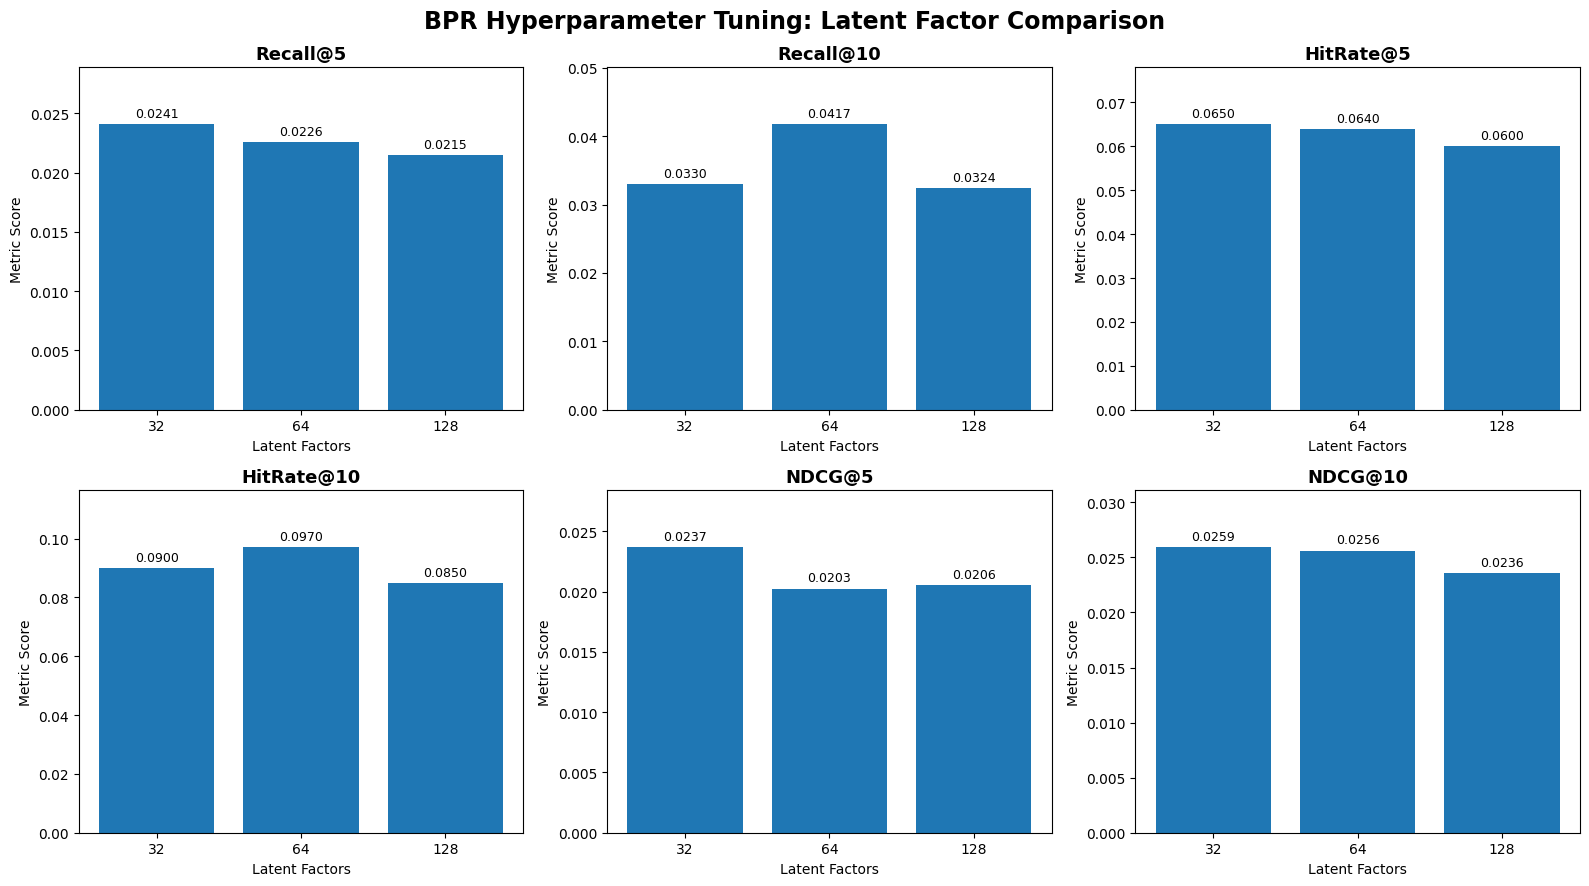

Chart saved to: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/results/bpr_latent_factor_comparison_reg_0.001.png


In [47]:
# Visualizing BPR Hyperparameter Tuning Results

import matplotlib.pyplot as plt

# Load the saved combined comparison
plot_df = pd.read_csv(
    results_dir / "bpr_combined_hyperparameter_comparison.csv"
)

metrics = [
    "Recall@5", "Recall@10",
    "HitRate@5", "HitRate@10",
    "NDCG@5", "NDCG@10"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, metric in zip(axes.flat, metrics):
    bars = ax.bar(
        plot_df["Latent Factors"].astype(str),
        plot_df[metric]
    )

    ax.set_title(metric, fontsize=13, fontweight="bold")
    ax.set_xlabel("Latent Factors")
    ax.set_ylabel("Metric Score")
    ax.set_ylim(0, plot_df[metric].max() * 1.2)

    # Display metric values above each bar
    ax.bar_label(
        bars,
        fmt="%.4f",
        padding=3,
        fontsize=9
    )

fig.suptitle(
    "BPR Hyperparameter Tuning: Latent Factor Comparison",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

# Save a high-resolution figure for the report
chart_path = (
    results_dir / "bpr_latent_factor_comparison_reg_0.001.png"
)

plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path)

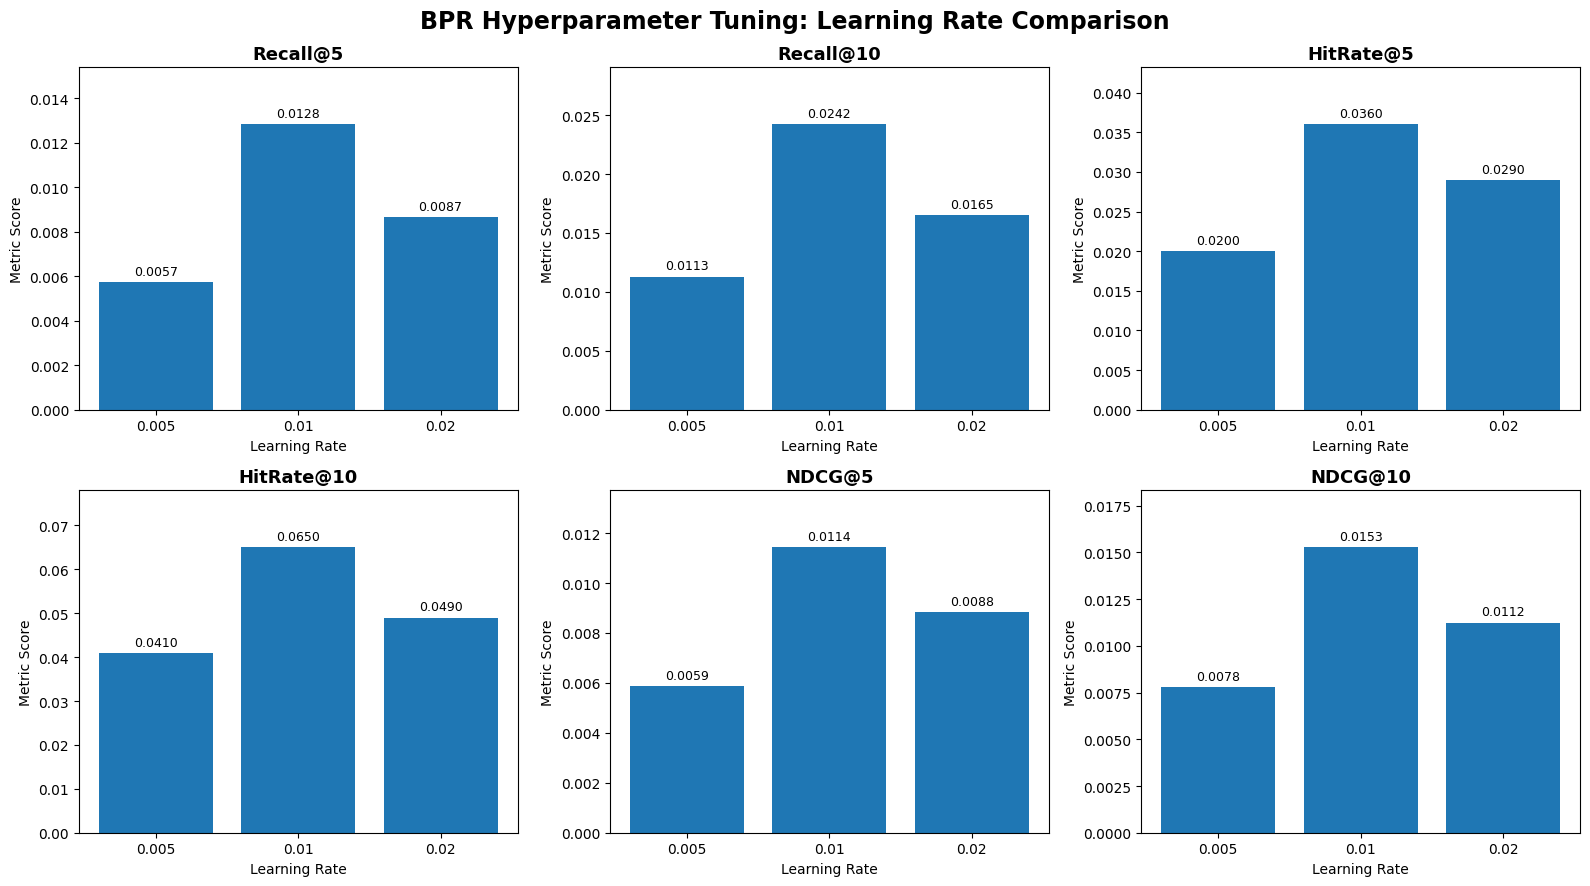

Chart saved to: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/results/bpr_learning_rate_comparison.png


In [48]:
#Visualizing the Effect of Learning Rate on BPR Performance

# Load saved learning rate comparison
learning_rate_plot_df = pd.read_csv(
    results_dir / "bpr_learning_rate_comparison.csv"
)

metrics = [
    "Recall@5", "Recall@10",
    "HitRate@5", "HitRate@10",
    "NDCG@5", "NDCG@10"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, metric in zip(axes.flat, metrics):
    bars = ax.bar(
        learning_rate_plot_df["Learning Rate"].astype(str),
        learning_rate_plot_df[metric]
    )

    ax.set_title(metric, fontsize=13, fontweight="bold")
    ax.set_xlabel("Learning Rate")
    ax.set_ylabel("Metric Score")
    ax.set_ylim(
        0,
        learning_rate_plot_df[metric].max() * 1.2
    )

    ax.bar_label(
        bars,
        fmt="%.4f",
        padding=3,
        fontsize=9
    )

fig.suptitle(
    "BPR Hyperparameter Tuning: Learning Rate Comparison",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

# Save a high-resolution image
learning_rate_chart_path = (
    results_dir / "bpr_learning_rate_comparison.png"
)

plt.savefig(
    learning_rate_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved to:", learning_rate_chart_path)


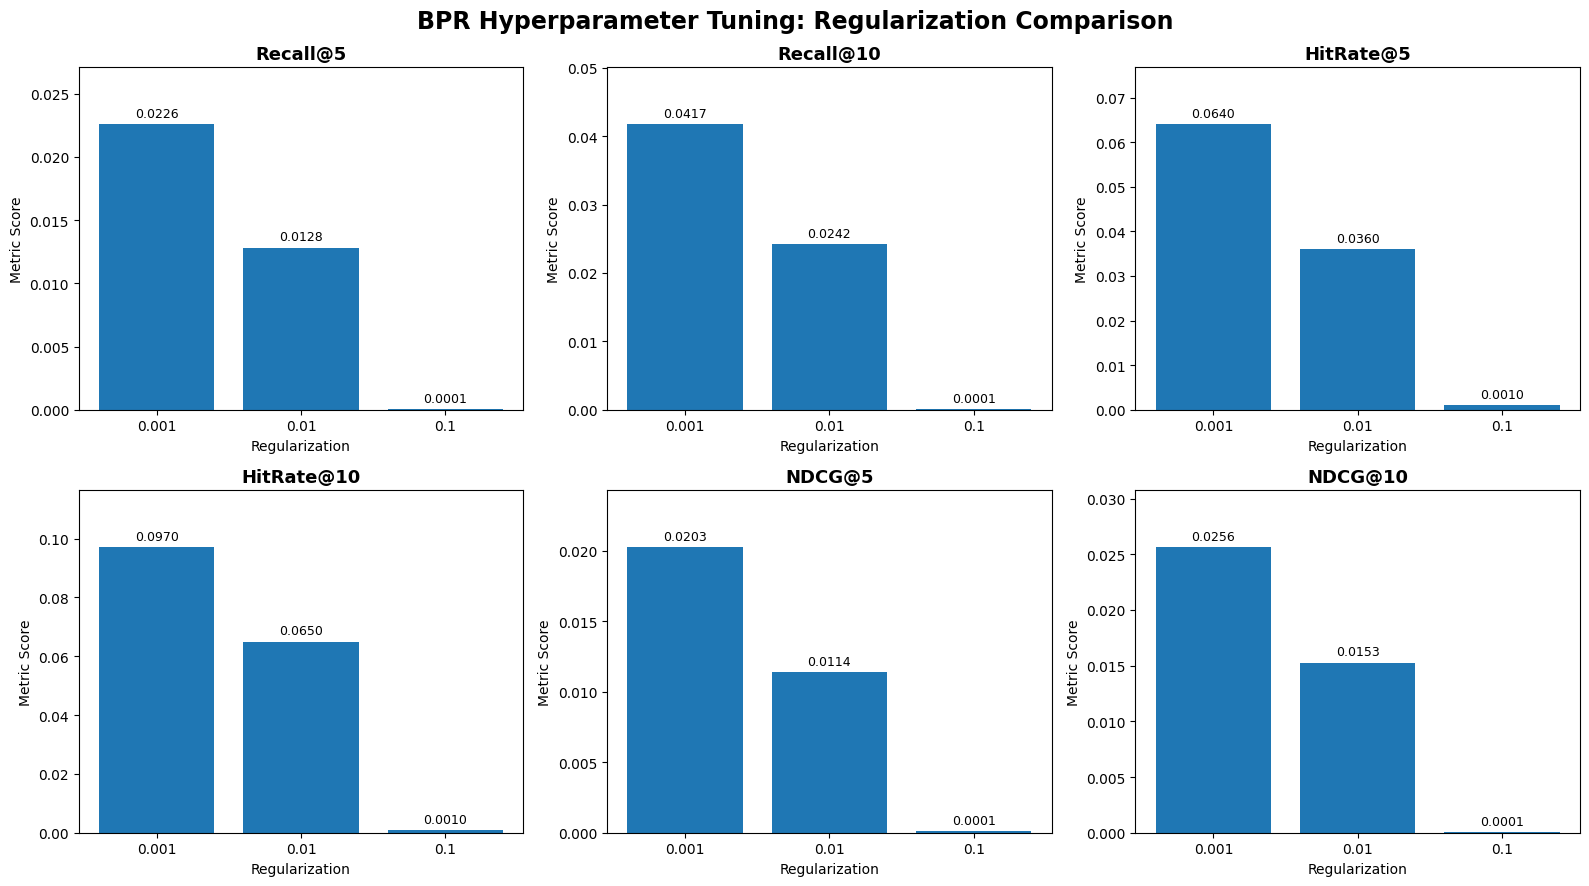

Chart saved to: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/results/bpr_regularization_comparison.png


In [49]:
# Visualizing the Effect of Regularization on BPR Performance

# Load the saved regularization comparison
regularization_plot_df = pd.read_csv(
    results_dir / "bpr_regularization_comparison.csv"
)

metrics = [
    "Recall@5", "Recall@10",
    "HitRate@5", "HitRate@10",
    "NDCG@5", "NDCG@10"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, metric in zip(axes.flat, metrics):
    bars = ax.bar(
        regularization_plot_df["Regularization"].astype(str),
        regularization_plot_df[metric]
    )

    ax.set_title(metric, fontsize=13, fontweight="bold")
    ax.set_xlabel("Regularization")
    ax.set_ylabel("Metric Score")

    ax.set_ylim(
        0,
        regularization_plot_df[metric].max() * 1.2
    )

    ax.bar_label(
        bars,
        fmt="%.4f",
        padding=3,
        fontsize=9
    )

fig.suptitle(
    "BPR Hyperparameter Tuning: Regularization Comparison",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

# Save a high-resolution image
regularization_chart_path = (
    results_dir / "bpr_regularization_comparison.png"
)

plt.savefig(
    regularization_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved to:", regularization_chart_path)

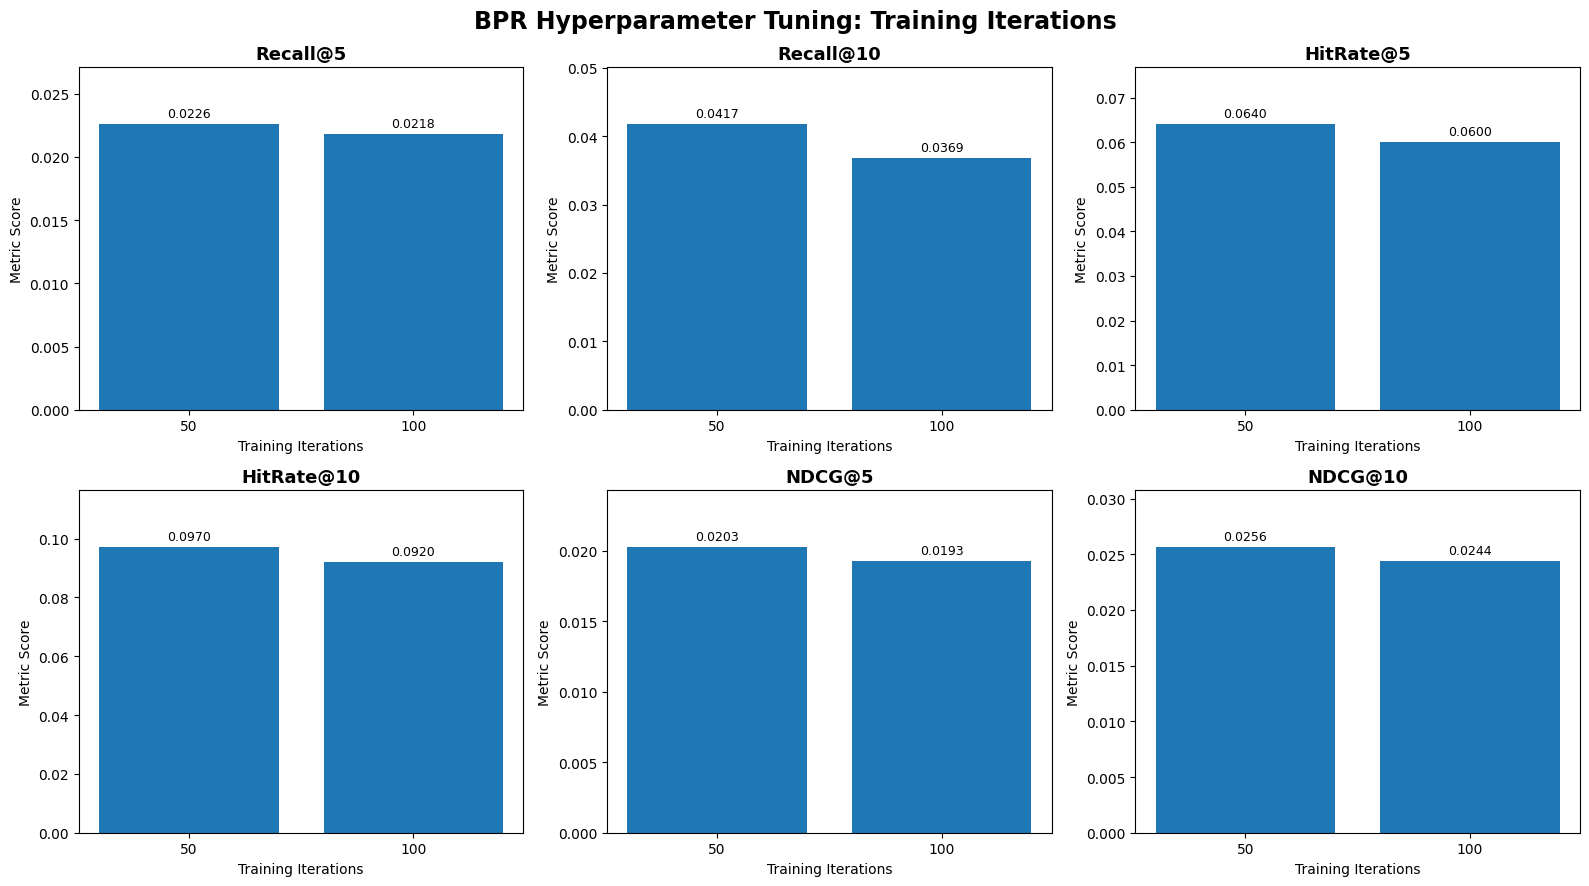

Chart saved to: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/results/bpr_iteration_comparison.png


In [50]:
#Visualizing the Effect of Training Iterations on BPR Performance

# Load the saved iteration comparison
iteration_plot_df = pd.read_csv(
    results_dir / "bpr_iteration_comparison.csv"
)

metrics = [
    "Recall@5", "Recall@10",
    "HitRate@5", "HitRate@10",
    "NDCG@5", "NDCG@10"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, metric in zip(axes.flat, metrics):
    bars = ax.bar(
        iteration_plot_df["Iterations"].astype(str),
        iteration_plot_df[metric]
    )

    ax.set_title(metric, fontsize=13, fontweight="bold")
    ax.set_xlabel("Training Iterations")
    ax.set_ylabel("Metric Score")

    ax.set_ylim(
        0,
        iteration_plot_df[metric].max() * 1.2
    )

    ax.bar_label(
        bars,
        fmt="%.4f",
        padding=3,
        fontsize=9
    )

fig.suptitle(
    "BPR Hyperparameter Tuning: Training Iterations",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

# Save a high-resolution image
iteration_chart_path = (
    results_dir / "bpr_iteration_comparison.png"
)

plt.savefig(
    iteration_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved to:", iteration_chart_path)